In [1]:
%load_ext autoreload
%autoreload 2
import os
import math
import random
import numpy as np
import random
import torch
import matplotlib.pyplot as plt

import draw,utils
import warnings
warnings.filterwarnings("ignore")

In [2]:
Train_filename = "Supervised_Train_syn2d_512.npy"
Valid_filename = "Supervised_Valid_syn2d_512.npy"
Modelname = "Supervised_syn2d_base_step2_200epoch"

In [3]:
num_sample = 4000
root_path = os.path.abspath(".")
dataset_name = 'dataset'
dataset_path = os.path.join(root_path,dataset_name)
train_dataset_path = os.path.join(dataset_path, "syn2d_512_segment")

if os.path.exists(os.path.join(dataset_path,Train_filename)) is False:
    sample_name_list = []
    for i in range(num_sample):
        train_sample_file = f'{i}'
        sample_name_list.append(train_sample_file)
    train_set_ratio = 0.79999
    num_data_sample = len(sample_name_list)
    # 打乱数据集
    random.shuffle(sample_name_list)

    # 训练集/验证集划分
    valid_num = int(num_data_sample * (1-train_set_ratio))
    valid_list = random.sample(sample_name_list, valid_num)

    samples_train,samples_valid = [],[]
    for sample_name in sample_name_list[:num_sample]:
        if sample_name not in valid_list:
            samples_train.append(sample_name)
        else:
            samples_valid.append(sample_name)
            
    print(f'训练样本数量：{len(samples_train)}')
    print(f'验证样本数量：{len(samples_valid)}')
    
    np.save(os.path.join(dataset_path,Train_filename), samples_train)
    np.save(os.path.join(dataset_path,Valid_filename), samples_valid)

In [4]:
os.environ['CUDA_VISIBLE_DEVICES']= '0,1'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    num_GPU = torch.cuda.device_count()
    print(f"GPU 数量: {num_GPU}")
print(f"运行平台: {device}")
root_path = os.path.abspath('.')

GPU 数量: 2
运行平台: cuda


In [5]:
samples_train = np.load(os.path.join(dataset_path, Train_filename), allow_pickle=True)
samples_valid = np.load(os.path.join(dataset_path, Valid_filename), allow_pickle=True)
print(f"训练样本数量: {len(samples_train)}")
print(f"验证样本数量: {len(samples_valid)}")

train_sample_path = os.path.join(dataset_path, "syn2d_512_segment")
input_attr_list = ["seis"]
rgt_attr_list = ["rgt"]
fault_attr_list = ["fault"]
prior_attr_list1=["segment"]
prior_attr_list2=["normal"]

训练样本数量: 3200
验证样本数量: 800


In [6]:
train_data =  utils.build_dataset_finetune(samples_train, train_sample_path, 'Train',
                                           input_attr_list = input_attr_list,
                                           prior_attr_list1 = prior_attr_list1,
                                           prior_attr_list2 = prior_attr_list2,
                                           output_attr_list = rgt_attr_list, 
                                           output_attr_list2 = fault_attr_list)
valid_data =  utils.build_dataset_finetune(samples_valid, train_sample_path, 'Valid',
                                           input_attr_list = input_attr_list,
                                           prior_attr_list1=prior_attr_list1,
                                           prior_attr_list2=prior_attr_list2,
                                           output_attr_list = rgt_attr_list, 
                                           output_attr_list2 = fault_attr_list)

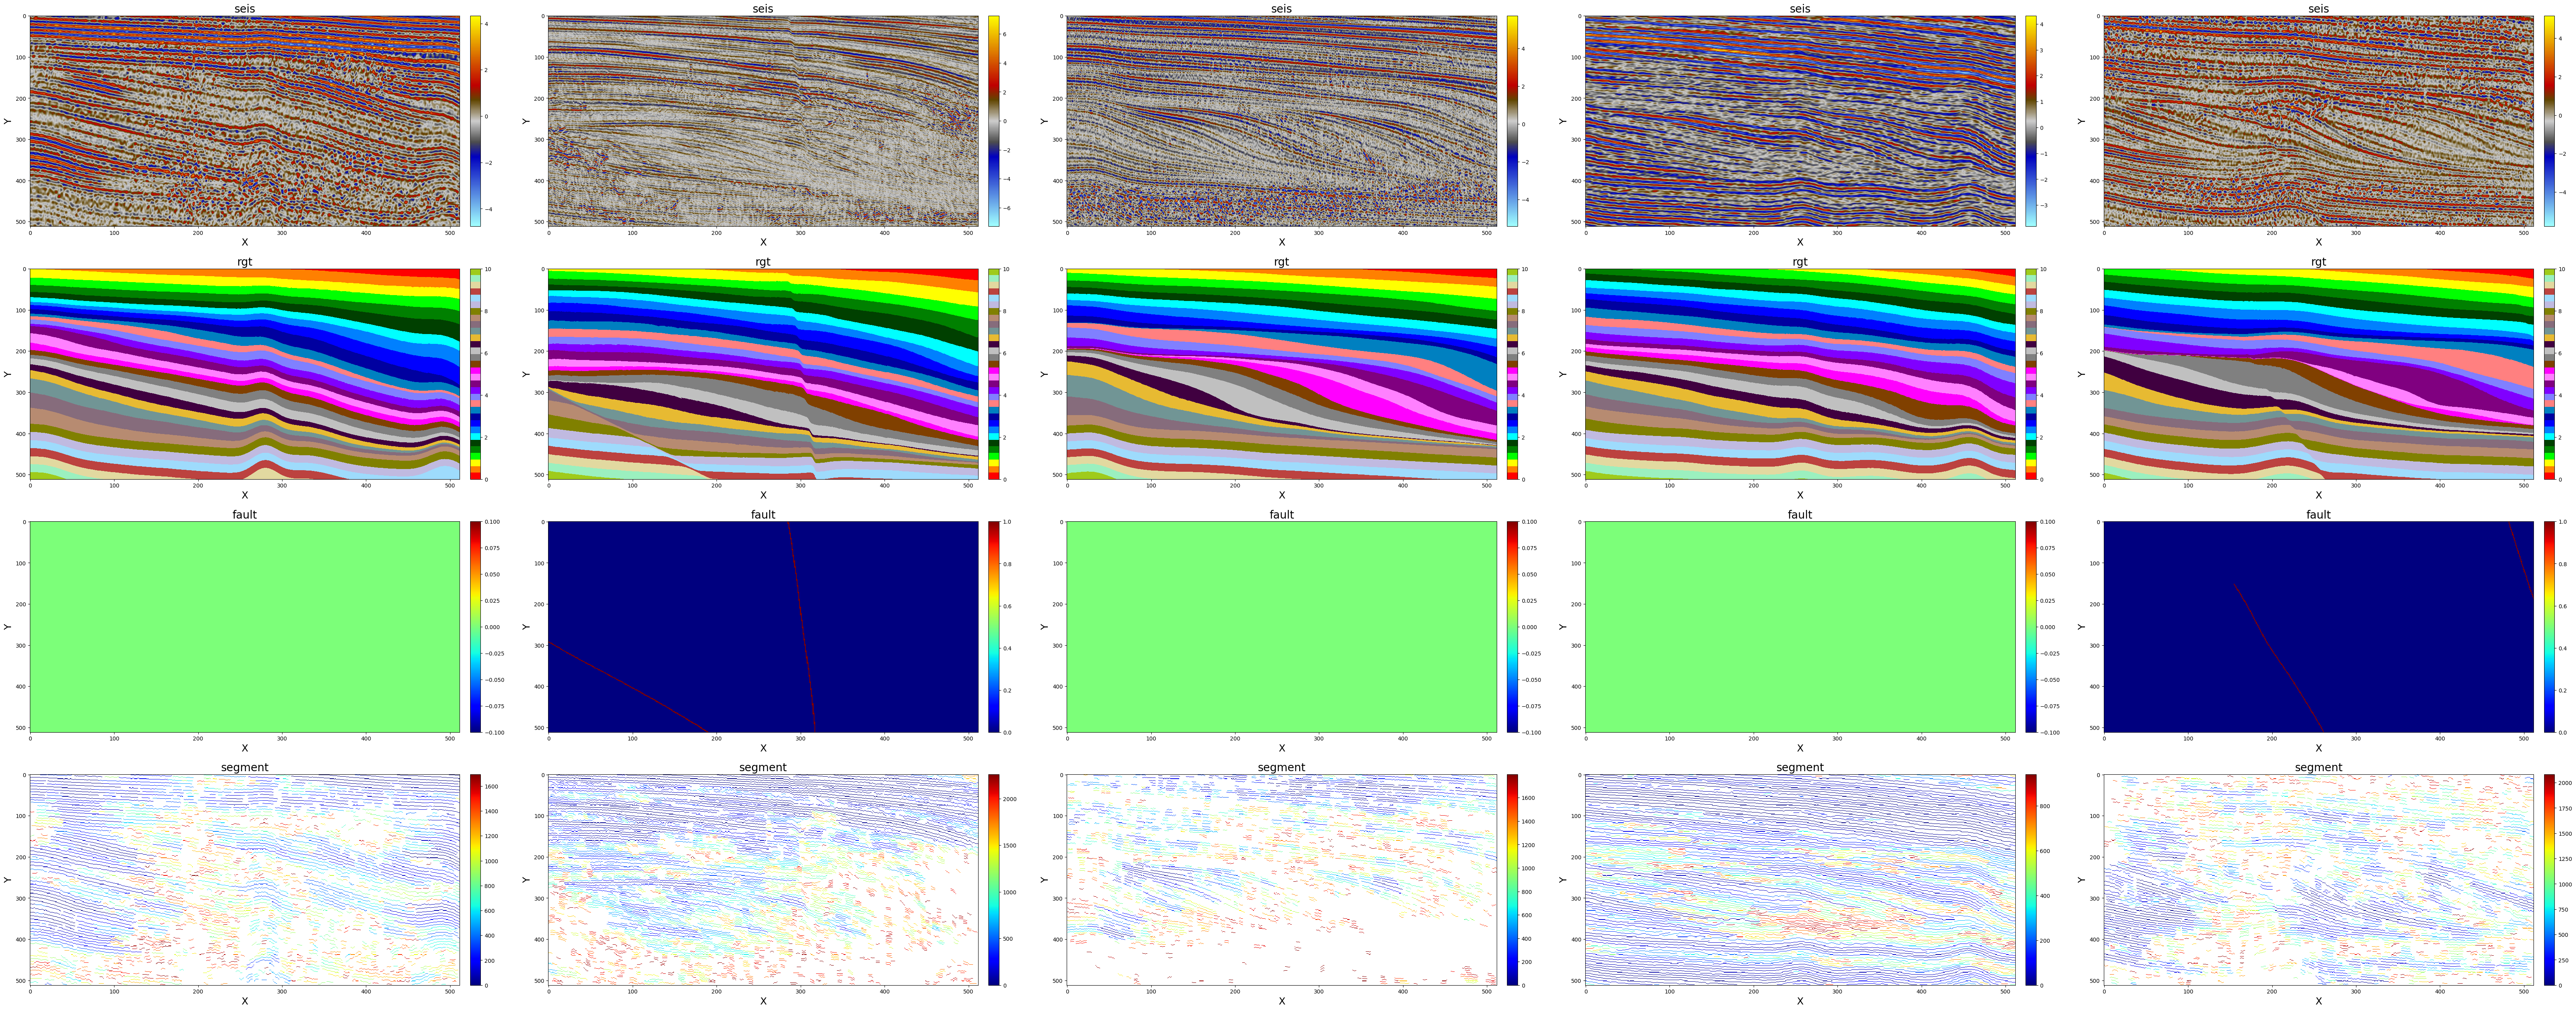

In [7]:
# plot
idxs = np.random.randint(0, len(train_data), size=5) 
batch_samples = [train_data[i] for i in idxs]
draw_attr_list = input_attr_list + rgt_attr_list + fault_attr_list + prior_attr_list1
draw.draw_samples(batch_samples, draw_attr_list, 
                  cmap=[utils.getPetrelColors(),utils.getStrataColors(),"jet",utils.setAlpha("jet",FillExceptMin=True)],
                  methods=["bilinear","bilinear","nearest","nearest"])

In [8]:
import SFM_pretrain.model_rgt as models_rgt

model = models_rgt.vit_base_patch16(img_size=512, in_chans=1, num_classes=1, drop_path_rate=0.1)
# state_dict = torch.load("./checkpoints/Pretrain_field2d_base/checkpoint-best.pth")['state_dict']
state_dict = torch.load("./checkpoints/Supervised_syn2d_base/checkpoint-best.pth")['state_dict']
new_state_dict = {k.replace('module.', ''): v for k, v in state_dict.items()} # 移除module.前缀
model.load_state_dict(new_state_dict)

# 并行模式
if torch.cuda.is_available():
    model = torch.nn.DataParallel(model, device_ids=range(num_GPU)).to(device)
else:
    model = model.to(device)
    
# 模型保存路径
checkpoint_path = os.path.join('checkpoints', Modelname)
if not os.path.exists(checkpoint_path):
    os.makedirs(checkpoint_path)
print(f"模型读取路径: {checkpoint_path}")

模型读取路径: checkpoints/Supervised_syn2d_base_step2_200epoch


In [9]:
# 定义训练参数
param = {}
param['epochs'] = 201     # 训练轮数
param['batch_size'] = 32   # 批大小
param['lr'] = 1e-3         # 学习率
# SGD
param['gamma'] = 0.9      # 学习率衰减系数
param['step_size'] = 50  # 学习率衰减间隔
param['momentum'] = 0.8    # 动量
# Adam
param['lr_factor'] = 0.5 # 学习因子
param['lr_patience'] = 2 # 容忍因子
param['weight_decay'] = 0 # 权重衰减(1e-4)

param['optimizer_type'] = 'Adam' # 优化器类型
param['checkpoint_path'] = checkpoint_path
param['disp_inter'] = 1 # 显示间隔
param['save_inter'] = 20 # 保存间隔

Epoch:0, TrainLoss:0.423269 <0.0572 & 0.0549 & 0.2357 & 0.0755>, ValidLoss: 0.337902, Learning rate: 0.001000
Epoch:1, TrainLoss:0.320043 <0.0234 & 0.0456 & 0.1827 & 0.0684>, ValidLoss: 0.343633, Learning rate: 0.001000
Epoch:2, TrainLoss:0.316900 <0.0243 & 0.0453 & 0.1802 & 0.0671>, ValidLoss: 0.329232, Learning rate: 0.001000
Epoch:3, TrainLoss:0.297642 <0.0210 & 0.0440 & 0.1662 & 0.0664>, ValidLoss: 0.309853, Learning rate: 0.001000
Epoch:4, TrainLoss:0.297207 <0.0207 & 0.0440 & 0.1664 & 0.0661>, ValidLoss: 0.305464, Learning rate: 0.001000
Epoch:5, TrainLoss:0.294784 <0.0221 & 0.0444 & 0.1617 & 0.0666>, ValidLoss: 0.310231, Learning rate: 0.001000
Epoch:6, TrainLoss:0.284932 <0.0203 & 0.0441 & 0.1547 & 0.0659>, ValidLoss: 0.328046, Learning rate: 0.001000
Epoch:7, TrainLoss:0.281686 <0.0201 & 0.0438 & 0.1520 & 0.0658>, ValidLoss: 0.323805, Learning rate: 0.001000
Epoch:8, TrainLoss:0.285759 <0.0215 & 0.0443 & 0.1540 & 0.0660>, ValidLoss: 0.315190, Learning rate: 0.001000
Epoch:9, T

Epoch:74, TrainLoss:0.182058 <0.0058 & 0.0370 & 0.0847 & 0.0546>, ValidLoss: 0.221531, Learning rate: 0.000063
Epoch:75, TrainLoss:0.181637 <0.0057 & 0.0369 & 0.0844 & 0.0546>, ValidLoss: 0.221608, Learning rate: 0.000063
Epoch:76, TrainLoss:0.182174 <0.0057 & 0.0369 & 0.0850 & 0.0546>, ValidLoss: 0.221823, Learning rate: 0.000063
Epoch:77, TrainLoss:0.181354 <0.0057 & 0.0369 & 0.0843 & 0.0545>, ValidLoss: 0.220768, Learning rate: 0.000063
Epoch:78, TrainLoss:0.181794 <0.0058 & 0.0369 & 0.0847 & 0.0545>, ValidLoss: 0.221004, Learning rate: 0.000063
Epoch:79, TrainLoss:0.181100 <0.0056 & 0.0368 & 0.0842 & 0.0544>, ValidLoss: 0.221656, Learning rate: 0.000063
Epoch:80, TrainLoss:0.181004 <0.0056 & 0.0368 & 0.0841 & 0.0544>, ValidLoss: 0.220457, Learning rate: 0.000063
Epoch:81, TrainLoss:0.180880 <0.0057 & 0.0368 & 0.0841 & 0.0544>, ValidLoss: 0.220895, Learning rate: 0.000063
Epoch:82, TrainLoss:0.180853 <0.0056 & 0.0367 & 0.0841 & 0.0543>, ValidLoss: 0.221293, Learning rate: 0.000063
E

Epoch:148, TrainLoss:0.173367 <0.0050 & 0.0358 & 0.0794 & 0.0532>, ValidLoss: 0.218877, Learning rate: 0.000002
Epoch:149, TrainLoss:0.173148 <0.0050 & 0.0357 & 0.0793 & 0.0531>, ValidLoss: 0.218869, Learning rate: 0.000002
Epoch:150, TrainLoss:0.173367 <0.0050 & 0.0358 & 0.0794 & 0.0531>, ValidLoss: 0.218751, Learning rate: 0.000002
Epoch:151, TrainLoss:0.173256 <0.0050 & 0.0358 & 0.0794 & 0.0531>, ValidLoss: 0.218763, Learning rate: 0.000002
Epoch:152, TrainLoss:0.173383 <0.0050 & 0.0357 & 0.0794 & 0.0532>, ValidLoss: 0.218658, Learning rate: 0.000002
Epoch:153, TrainLoss:0.173371 <0.0050 & 0.0358 & 0.0794 & 0.0532>, ValidLoss: 0.218714, Learning rate: 0.000001
Epoch:154, TrainLoss:0.173410 <0.0050 & 0.0358 & 0.0794 & 0.0532>, ValidLoss: 0.218958, Learning rate: 0.000001
Epoch:155, TrainLoss:0.173549 <0.0051 & 0.0358 & 0.0795 & 0.0532>, ValidLoss: 0.218809, Learning rate: 0.000001
Epoch:156, TrainLoss:0.173406 <0.0050 & 0.0358 & 0.0795 & 0.0531>, ValidLoss: 0.218760, Learning rate: 0

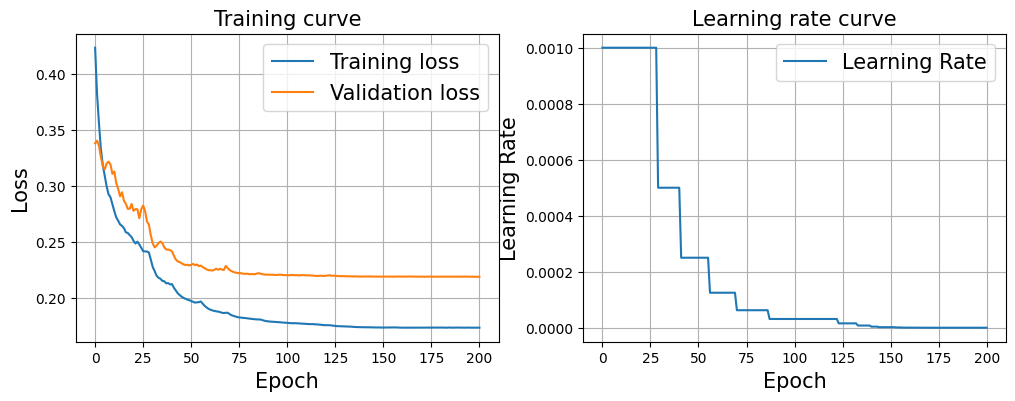

log has saved


In [10]:
model = utils.supervised_train_stage2_RL(param, model, train_data, valid_data, input_attrs=["seis"],
                                         prior_attrs1=["segment"],prior_attrs2=["normal"],
                                         output_attrs=["rgt"],output_attrs2=["fault"],plot=True)

In [11]:
quit()